# Housing price prediction: regression models
Target: `price`. Every model you run is added to one cumulative comparison table.

In [4]:
import os
cwd = os.getcwd()
print(cwd)
#change it 


os.chdir(r"C:\Users\saghr\Downloads\python\c3")

c:\Users\saghr\Downloads


## 1. Import the libraries

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## 2. Load and explore the dataset

500 rows, 8 predictors + the target price. No missing values, no duplicates, everything is numeric.

In [6]:
df = pd.read_csv("housing_regression_dataset.csv")

print(df.shape)                 # (500, 9)
display(df.head())              # first 5 rows
df.info()                       # column names, types, non-null counts
display(df.describe().T)        # descriptive statistics
print(df.isnull().sum())        # missing values per column
print(df.duplicated().sum())    # duplicate rows

(500, 9)


,square_feet,bedrooms,bathrooms,age_years,distance_to_city_center_km,garage_capacity,has_pool,neighborhood_rating,price
0,2048,3,3.0,22,17.8,3,0,6,403000
1,1731,3,1.0,25,16.0,1,0,10,351500
2,2124,3,2.5,3,1.7,0,0,8,439100
3,2562,5,1.0,17,22.6,2,0,8,444100
4,1683,3,1.5,5,22.8,1,0,6,337000


<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   square_feet                 500 non-null    int64  
 1   bedrooms                    500 non-null    int64  
 2   bathrooms                   500 non-null    float64
 3   age_years                   500 non-null    int64  
 4   distance_to_city_center_km  500 non-null    float64
 5   garage_capacity             500 non-null    int64  
 6   has_pool                    500 non-null    int64  
 7   neighborhood_rating         500 non-null    int64  
 8   price                       500 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 35.3 KB


,count,mean,std,min,25%,50%,75%,max
square_feet,500.0,1804.4900,487.631339,600.0,1449.750,1806.5,2118.500,3726.0
bedrooms,500.0,2.8440,0.984684,1.0,2.000,3.0,4.000,5.0
bathrooms,500.0,1.9930,0.684389,1.0,1.500,2.0,2.500,3.5
age_years,500.0,24.2060,14.063397,0.0,13.000,23.0,36.000,49.0
distance_to_city_center_km,500.0,12.5644,7.211779,0.5,6.175,12.2,19.025,25.0
garage_capacity,500.0,1.3380,0.892945,0.0,1.000,1.0,2.000,3.0
has_pool,500.0,0.2580,0.437972,0.0,0.000,0.0,1.000,1.0
neighborhood_rating,500.0,5.6560,2.870216,1.0,3.000,6.0,8.000,10.0
price,500.0,340985.0000,74176.018216,131500.0,292500.000,336850.0,390875.000,633400.0


square_feet                   0
bedrooms                      0
bathrooms                     0
age_years                     0
distance_to_city_center_km    0
garage_capacity               0
has_pool                      0
neighborhood_rating           0
price                         0
dtype: int64
0


price                         1.000000
square_feet                   0.779812
neighborhood_rating           0.311104
bedrooms                      0.222565
garage_capacity               0.152718
has_pool                      0.139864
bathrooms                     0.134096
age_years                    -0.160030
distance_to_city_center_km   -0.280434
Name: price, dtype: float64


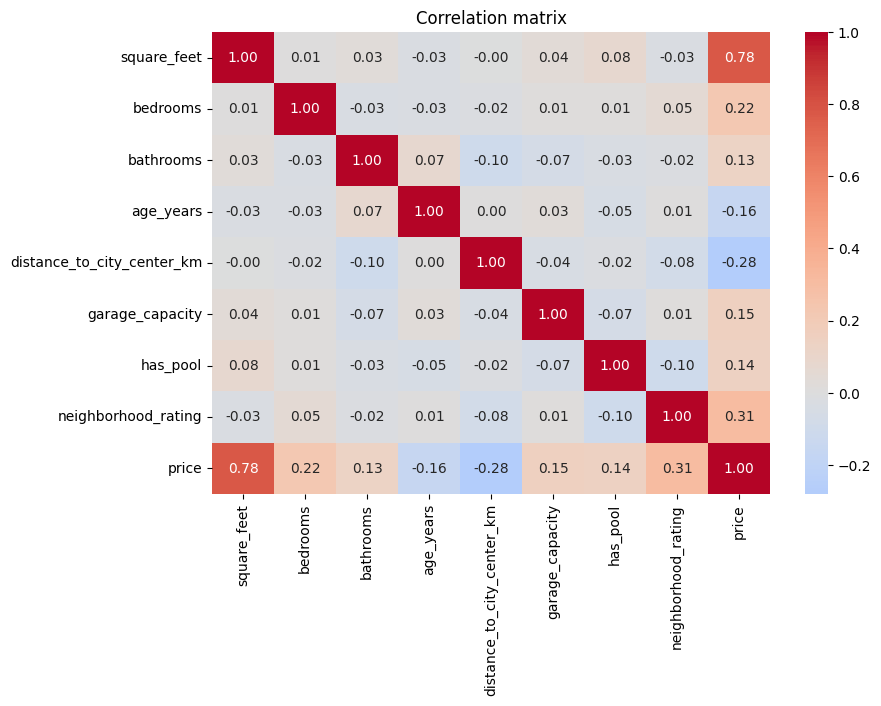

In [7]:
corr = df.corr(numeric_only=True)
print(corr["price"].sort_values(ascending=False))   # correlation with the target

plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

## 3. Clean the data

Nothing to fix here: no missing values, all columns numeric, so no dropna / fillna / get_dummies.

In [8]:
df = df.drop_duplicates()   # safety check, removes 0 rows here
print(df.shape)

(500, 9)


## 4. Define X and y

In [9]:
X = df.drop("price", axis=1)   # predictors
y = df["price"]                # target: house price

## 5. Split the dataset (80% train / 20% test)

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)
print(X_train.shape, X_test.shape)   # (400, 8) (100, 8)

(400, 8) (100, 8)


## 6. Evaluation helper + cumulative results table

Run once. Each call to evaluate_model() trains the model, scores it on the test set, runs 5-fold cross-validation on the training set, and adds a row to the table. The table keeps every model so far.

In [11]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
results = pd.DataFrame()

def evaluate_model(name, model):
    global results

    # K-fold cross-validation on the TRAINING data only
    cv_scores = cross_val_score(model, X_train, y_train, cv=kfold, scoring="r2")

    # Final fit, evaluation on the TEST data
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    row = pd.DataFrame({
        "MAE":        [mean_absolute_error(y_test, y_pred)],
        "MSE":        [mse],
        "RMSE":       [np.sqrt(mse)],
        "R2 (test)":  [r2_score(y_test, y_pred)],
        "CV R2 mean": [cv_scores.mean()],
        "CV R2 std":  [cv_scores.std()],
    }, index=[name])

    # replace the row if the model was already evaluated
    results = pd.concat([results.drop(index=name, errors="ignore"), row])
    display(results.round(4))
    return y_pred

def plot_predictions(y_pred, title):
    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, y_pred, alpha=0.6)
    lims = [y_test.min(), y_test.max()]
    plt.plot(lims, lims, "r--")            # perfect-prediction line
    plt.xlabel("Actual price")
    plt.ylabel("Predicted price")
    plt.title(title)
    plt.show()

## 7. The regression models

Add them one at a time: the table above grows after each cell.

## A. Linear Regression

Fits a straight-line relationship. The simplest baseline and the easiest to interpret. No scaling needed.

,MAE,MSE,RMSE,R2 (test),CV R2 mean,CV R2 std
Linear Regression,19225.8568,6.384747e+08,25268.0577,0.8938,0.8685,0.0069


Intercept: 47426.82


distance_to_city_center_km    -2314.42
age_years                      -815.11
square_feet                     114.33
neighborhood_rating            8233.24
garage_capacity               10782.46
bathrooms                     13700.83
bedrooms                      15148.59
has_pool                      18938.77
dtype: float64

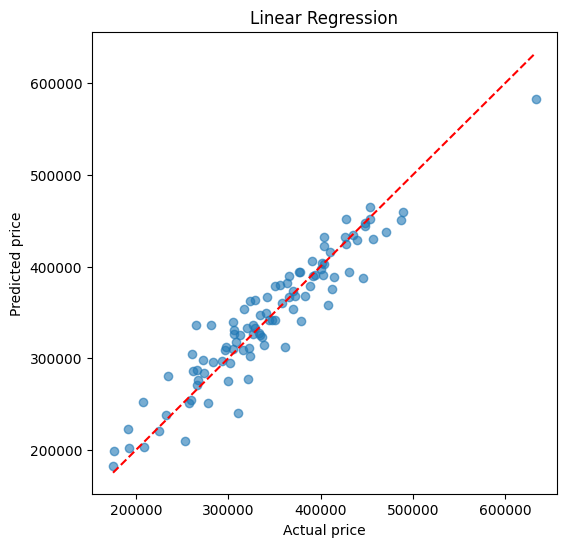

In [12]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
y_pred_lin = evaluate_model("Linear Regression", lin_reg)

coefs = pd.Series(lin_reg.coef_, index=X.columns).sort_values()
print("Intercept:", round(lin_reg.intercept_, 2))
display(coefs.round(2))     # effect on price of +1 unit of each predictor
plot_predictions(y_pred_lin, "Linear Regression")

## B. Ridge Regression

Linear regression with a penalty that shrinks coefficients (helps against overfitting). Higher alpha = stronger shrinkage. Needs scaling.

In [13]:
from sklearn.linear_model import Ridge

ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
y_pred_ridge = evaluate_model("Ridge", ridge)

,MAE,MSE,RMSE,R2 (test),CV R2 mean,CV R2 std
Linear Regression,19225.8568,6.384747e+08,25268.0577,0.8938,0.8685,0.0069
Ridge,19248.4426,6.394348e+08,25287.0484,0.8936,0.8686,0.0068


## C. Lasso Regression

Like Ridge, but can shrink some coefficients to exactly zero, which acts as feature selection. Needs scaling.

In [14]:
from sklearn.linear_model import Lasso

lasso = make_pipeline(StandardScaler(), Lasso(alpha=0.1))
y_pred_lasso = evaluate_model("Lasso", lasso)

,MAE,MSE,RMSE,R2 (test),CV R2 mean,CV R2 std
Linear Regression,19225.8568,6.384747e+08,25268.0577,0.8938,0.8685,0.0069
Ridge,19248.4426,6.394348e+08,25287.0484,0.8936,0.8686,0.0068
Lasso,19225.8880,6.384742e+08,25268.0464,0.8938,0.8685,0.0069


## D. Elastic Net Regression

Mix of Ridge and Lasso. l1_ratio=1 is Lasso-like, l1_ratio=0 is Ridge-like. Needs scaling.

In [15]:
from sklearn.linear_model import ElasticNet

enet = make_pipeline(StandardScaler(), ElasticNet(alpha=0.1, l1_ratio=0.5))
y_pred_enet = evaluate_model("Elastic Net", enet)

,MAE,MSE,RMSE,R2 (test),CV R2 mean,CV R2 std
Linear Regression,19225.8568,6.384747e+08,25268.0577,0.8938,0.8685,0.0069
Ridge,19248.4426,6.394348e+08,25287.0484,0.8936,0.8686,0.0068
Lasso,19225.8880,6.384742e+08,25268.0464,0.8938,0.8685,0.0069
Elastic Net,19739.3896,6.674329e+08,25834.7219,0.8890,0.8670,0.0048


## E. Polynomial Regression

Adds squared terms and interactions to capture curved relationships. Higher degrees can overfit.

In [16]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

poly = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    LinearRegression()
)
y_pred_poly = evaluate_model("Polynomial (deg 2)", poly)

,MAE,MSE,RMSE,R2 (test),CV R2 mean,CV R2 std
Linear Regression,19225.8568,6.384747e+08,25268.0577,0.8938,0.8685,0.0069
Ridge,19248.4426,6.394348e+08,25287.0484,0.8936,0.8686,0.0068
Lasso,19225.8880,6.384742e+08,25268.0464,0.8938,0.8685,0.0069
Elastic Net,19739.3896,6.674329e+08,25834.7219,0.8890,0.8670,0.0048
Polynomial (deg 2),21450.1268,7.378453e+08,27163.3084,0.8772,0.8516,0.0172


## F. Decision Tree Regression

Splits the data into groups with simple rules. A very deep tree overfits, so limit max_depth. No scaling needed.

In [17]:
from sklearn.tree import DecisionTreeRegressor

tree = DecisionTreeRegressor(max_depth=5, random_state=42)
y_pred_tree = evaluate_model("Decision Tree", tree)

,MAE,MSE,RMSE,R2 (test),CV R2 mean,CV R2 std
Linear Regression,19225.8568,6.384747e+08,25268.0577,0.8938,0.8685,0.0069
Ridge,19248.4426,6.394348e+08,25287.0484,0.8936,0.8686,0.0068
Lasso,19225.8880,6.384742e+08,25268.0464,0.8938,0.8685,0.0069
Elastic Net,19739.3896,6.674329e+08,25834.7219,0.8890,0.8670,0.0048
Polynomial (deg 2),21450.1268,7.378453e+08,27163.3084,0.8772,0.8516,0.0172
Decision Tree,32018.0288,1.616798e+09,40209.4252,0.7310,0.5589,0.0346


## G. Random Forest Regression

Averages many decision trees. Handles nonlinear relationships well. No scaling needed.

,MAE,MSE,RMSE,R2 (test),CV R2 mean,CV R2 std
Linear Regression,19225.8568,6.384747e+08,25268.0577,0.8938,0.8685,0.0069
Ridge,19248.4426,6.394348e+08,25287.0484,0.8936,0.8686,0.0068
Lasso,19225.8880,6.384742e+08,25268.0464,0.8938,0.8685,0.0069
Elastic Net,19739.3896,6.674329e+08,25834.7219,0.8890,0.8670,0.0048
Polynomial (deg 2),21450.1268,7.378453e+08,27163.3084,0.8772,0.8516,0.0172
Decision Tree,32018.0288,1.616798e+09,40209.4252,0.7310,0.5589,0.0346
Random Forest,30555.4771,1.496847e+09,38689.1118,0.7510,0.7353,0.0244


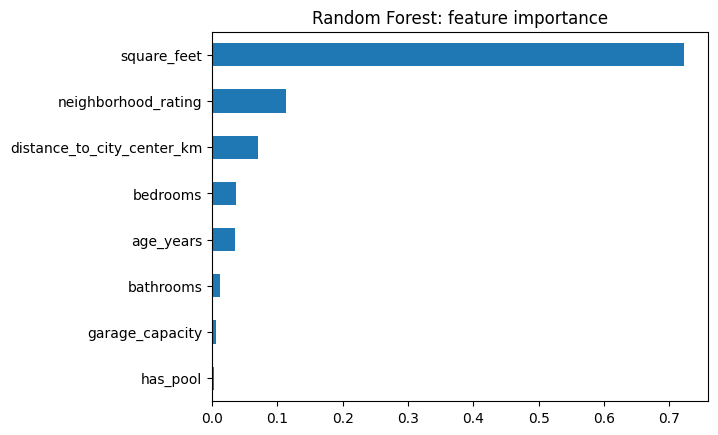

In [18]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
y_pred_rf = evaluate_model("Random Forest", rf)

# Which features matter most?
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", title="Random Forest: feature importance")
plt.show()

## H. Gradient Boosting Regression

Builds trees one after another; each new tree corrects the errors of the previous ones. No scaling needed.

In [19]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(
    n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42
)
y_pred_gb = evaluate_model("Gradient Boosting", gb)

,MAE,MSE,RMSE,R2 (test),CV R2 mean,CV R2 std
Linear Regression,19225.8568,6.384747e+08,25268.0577,0.8938,0.8685,0.0069
Ridge,19248.4426,6.394348e+08,25287.0484,0.8936,0.8686,0.0068
Lasso,19225.8880,6.384742e+08,25268.0464,0.8938,0.8685,0.0069
Elastic Net,19739.3896,6.674329e+08,25834.7219,0.8890,0.8670,0.0048
Polynomial (deg 2),21450.1268,7.378453e+08,27163.3084,0.8772,0.8516,0.0172
Decision Tree,32018.0288,1.616798e+09,40209.4252,0.7310,0.5589,0.0346
Random Forest,30555.4771,1.496847e+09,38689.1118,0.7510,0.7353,0.0244
Gradient Boosting,27733.8575,1.162394e+09,34093.9052,0.8066,0.8171,0.0136


## I. AdaBoost Regression

Combines many weak models and gives more weight to observations that are hard to predict.

In [20]:
from sklearn.ensemble import AdaBoostRegressor

ada = AdaBoostRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
y_pred_ada = evaluate_model("AdaBoost", ada)

,MAE,MSE,RMSE,R2 (test),CV R2 mean,CV R2 std
Linear Regression,19225.8568,6.384747e+08,25268.0577,0.8938,0.8685,0.0069
Ridge,19248.4426,6.394348e+08,25287.0484,0.8936,0.8686,0.0068
Lasso,19225.8880,6.384742e+08,25268.0464,0.8938,0.8685,0.0069
Elastic Net,19739.3896,6.674329e+08,25834.7219,0.8890,0.8670,0.0048
Polynomial (deg 2),21450.1268,7.378453e+08,27163.3084,0.8772,0.8516,0.0172
Decision Tree,32018.0288,1.616798e+09,40209.4252,0.7310,0.5589,0.0346
Random Forest,30555.4771,1.496847e+09,38689.1118,0.7510,0.7353,0.0244
Gradient Boosting,27733.8575,1.162394e+09,34093.9052,0.8066,0.8171,0.0136
AdaBoost,32190.0256,1.657809e+09,40716.2027,0.7242,0.7221,0.0359


## J. Extra Trees Regression

Like Random Forest, with extra randomness when building the trees. No scaling needed.

In [21]:
from sklearn.ensemble import ExtraTreesRegressor

et = ExtraTreesRegressor(n_estimators=100, random_state=42)
y_pred_et = evaluate_model("Extra Trees", et)

,MAE,MSE,RMSE,R2 (test),CV R2 mean,CV R2 std
Linear Regression,19225.8568,6.384747e+08,25268.0577,0.8938,0.8685,0.0069
Ridge,19248.4426,6.394348e+08,25287.0484,0.8936,0.8686,0.0068
Lasso,19225.8880,6.384742e+08,25268.0464,0.8938,0.8685,0.0069
Elastic Net,19739.3896,6.674329e+08,25834.7219,0.8890,0.8670,0.0048
Polynomial (deg 2),21450.1268,7.378453e+08,27163.3084,0.8772,0.8516,0.0172
Decision Tree,32018.0288,1.616798e+09,40209.4252,0.7310,0.5589,0.0346
Random Forest,30555.4771,1.496847e+09,38689.1118,0.7510,0.7353,0.0244
Gradient Boosting,27733.8575,1.162394e+09,34093.9052,0.8066,0.8171,0.0136
AdaBoost,32190.0256,1.657809e+09,40716.2027,0.7242,0.7221,0.0359
Extra Trees,26615.5900,1.257213e+09,35457.2023,0.7908,0.7930,0.0189


## K. K-Nearest Neighbors Regression

Predicts the average price of the K most similar houses. Uses distances, so scaling is essential.

In [22]:
from sklearn.neighbors import KNeighborsRegressor

knn = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5))
y_pred_knn = evaluate_model("KNN", knn)

,MAE,MSE,RMSE,R2 (test),CV R2 mean,CV R2 std
Linear Regression,19225.8568,6.384747e+08,25268.0577,0.8938,0.8685,0.0069
Ridge,19248.4426,6.394348e+08,25287.0484,0.8936,0.8686,0.0068
Lasso,19225.8880,6.384742e+08,25268.0464,0.8938,0.8685,0.0069
Elastic Net,19739.3896,6.674329e+08,25834.7219,0.8890,0.8670,0.0048
Polynomial (deg 2),21450.1268,7.378453e+08,27163.3084,0.8772,0.8516,0.0172
Decision Tree,32018.0288,1.616798e+09,40209.4252,0.7310,0.5589,0.0346
Random Forest,30555.4771,1.496847e+09,38689.1118,0.7510,0.7353,0.0244
Gradient Boosting,27733.8575,1.162394e+09,34093.9052,0.8066,0.8171,0.0136
AdaBoost,32190.0256,1.657809e+09,40716.2027,0.7242,0.7221,0.0359
Extra Trees,26615.5900,1.257213e+09,35457.2023,0.7908,0.7930,0.0189


## L. Support Vector Regression (SVR)

Needs scaling. Prices are in the hundreds of thousands, so the target is scaled too (TransformedTargetRegressor); without it SVR with default C and epsilon performs very poorly.

In [23]:
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor

svr = TransformedTargetRegressor(
    regressor=make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10, epsilon=0.1)),
    transformer=StandardScaler()
)
y_pred_svr = evaluate_model("SVR", svr)

,MAE,MSE,RMSE,R2 (test),CV R2 mean,CV R2 std
Linear Regression,19225.8568,6.384747e+08,25268.0577,0.8938,0.8685,0.0069
Ridge,19248.4426,6.394348e+08,25287.0484,0.8936,0.8686,0.0068
Lasso,19225.8880,6.384742e+08,25268.0464,0.8938,0.8685,0.0069
Elastic Net,19739.3896,6.674329e+08,25834.7219,0.8890,0.8670,0.0048
Polynomial (deg 2),21450.1268,7.378453e+08,27163.3084,0.8772,0.8516,0.0172
Decision Tree,32018.0288,1.616798e+09,40209.4252,0.7310,0.5589,0.0346
Random Forest,30555.4771,1.496847e+09,38689.1118,0.7510,0.7353,0.0244
Gradient Boosting,27733.8575,1.162394e+09,34093.9052,0.8066,0.8171,0.0136
AdaBoost,32190.0256,1.657809e+09,40716.2027,0.7242,0.7221,0.0359
Extra Trees,26615.5900,1.257213e+09,35457.2023,0.7908,0.7930,0.0189


## 8. Compare all the models

Sorted by test R2. The CV columns tell you how stable each model is.

,MAE,MSE,RMSE,R2 (test),CV R2 mean,CV R2 std
Lasso,19225.8880,6.384742e+08,25268.0464,0.8938,0.8685,0.0069
Linear Regression,19225.8568,6.384747e+08,25268.0577,0.8938,0.8685,0.0069
Ridge,19248.4426,6.394348e+08,25287.0484,0.8936,0.8686,0.0068
Elastic Net,19739.3896,6.674329e+08,25834.7219,0.8890,0.8670,0.0048
Polynomial (deg 2),21450.1268,7.378453e+08,27163.3084,0.8772,0.8516,0.0172
Gradient Boosting,27733.8575,1.162394e+09,34093.9052,0.8066,0.8171,0.0136
Extra Trees,26615.5900,1.257213e+09,35457.2023,0.7908,0.7930,0.0189
SVR,29838.8952,1.492750e+09,38636.1213,0.7516,0.7463,0.0284
Random Forest,30555.4771,1.496847e+09,38689.1118,0.7510,0.7353,0.0244
Decision Tree,32018.0288,1.616798e+09,40209.4252,0.7310,0.5589,0.0346


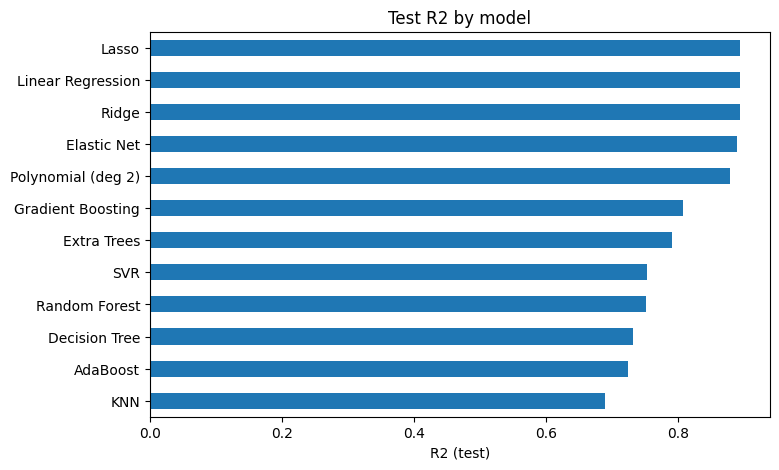

In [24]:
display(results.sort_values("R2 (test)", ascending=False).round(4))

results["R2 (test)"].sort_values().plot(kind="barh", figsize=(8, 5), title="Test R2 by model")
plt.xlabel("R2 (test)")
plt.show()

## 9. Improve the best model: Grid Search

Tests parameter combinations with 5-fold cross-validation on the training set only. Replace the model and the grid with the ones you want to tune.

In [25]:
params = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3, 4],
}

grid = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    params,
    cv=kfold,
    scoring="r2"
)
grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)

best_model = grid.best_estimator_
y_pred_best = evaluate_model("Gradient Boosting (tuned)", best_model)

{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200}
0.8250817550103788


,MAE,MSE,RMSE,R2 (test),CV R2 mean,CV R2 std
Linear Regression,19225.8568,6.384747e+08,25268.0577,0.8938,0.8685,0.0069
Ridge,19248.4426,6.394348e+08,25287.0484,0.8936,0.8686,0.0068
Lasso,19225.8880,6.384742e+08,25268.0464,0.8938,0.8685,0.0069
Elastic Net,19739.3896,6.674329e+08,25834.7219,0.8890,0.8670,0.0048
Polynomial (deg 2),21450.1268,7.378453e+08,27163.3084,0.8772,0.8516,0.0172
Decision Tree,32018.0288,1.616798e+09,40209.4252,0.7310,0.5589,0.0346
Random Forest,30555.4771,1.496847e+09,38689.1118,0.7510,0.7353,0.0244
Gradient Boosting,27733.8575,1.162394e+09,34093.9052,0.8066,0.8171,0.0136
AdaBoost,32190.0256,1.657809e+09,40716.2027,0.7242,0.7221,0.0359
Extra Trees,26615.5900,1.257213e+09,35457.2023,0.7908,0.7930,0.0189


## 10. Save and reload the model

In [26]:
import joblib

joblib.dump(best_model, "best_model.pkl")
loaded_model = joblib.load("best_model.pkl")
print(loaded_model.predict(X_test.head()))

[452452.91341429 465511.32839858 462136.9266822  343859.13912407
 307626.90404396]
